# 01 - Data Exploration

## Part A : Data understanding

### What each column means

| Column | Meaning | Why it may matter |
|---|---|---|
| `record_id` | ID of the row | Only a label, not used to predict |
| `machine_id` | Which machine | Groups rows by machine, not used to predict |
| `observation_timestamp` | When the reading was taken | Used to split data by time |
| `site` | Location of the machine (3 sites) | Some sites may be harsher |
| `machine_class` | Type of machine (4 types) | Some types may fail more often |
| `load_pct` | How hard the machine is working (%) | More load can mean more wear |
| `ambient_temp_c` | Air temperature around the machine (°C) | Hot surroundings add stress |
| `vibration_mm_s` | How much the machine shakes (mm/s) | Worn or loose parts shake more |
| `bearing_temp_c` | Temperature of the bearings (°C) | Damaged bearings rub and get hotter |
| `motor_current_a` | Electricity used by the motor (A) | A struggling machine uses more power |
| `discharge_pressure_kpa` | Pressure of the fluid pushed out (kPa) | A drop can mean wear or a leak |
| `corrective_orders_14d` | Number of repair jobs in the 14 days before the reading | Recent repairs may mean a problem |
| `unplanned_stops_14d` | Number of surprise stops in the 14 days before the reading | Recent trouble |
| `inspection_interval_days` | How often the machine is scheduled for checking (days) | A short interval may mean a machine under watch |
| `fails_within_7d` | **Target.** 1 = failed within 7 days after the reading, 0 = did not | What the model predicts |

1. Load data

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("../data/machine_observations.csv",
                 parse_dates=["observation_timestamp"])
df.head()

,record_id,machine_id,observation_timestamp,site,machine_class,load_pct,ambient_temp_c,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_kpa,corrective_orders_14d,unplanned_stops_14d,inspection_interval_days,fails_within_7d
0,REC-000001,M088,2024-01-01 01:08:00,North,A,54.8,14.7,2.51,56.0,50.0,601.0,0,0,30,0
1,REC-000002,M055,2024-01-01 01:51:00,North,B,57.7,18.5,3.78,57.1,68.3,495.8,0,0,30,0
2,REC-000003,M070,2024-01-01 02:02:00,North,A,77.2,13.1,2.94,53.4,61.6,569.0,0,2,30,0
3,REC-000004,M013,2024-01-01 02:34:00,North,A,75.2,14.0,2.45,56.4,63.3,662.0,0,1,30,0
4,REC-000005,M059,2024-01-01 02:44:00,Central,B,39.6,16.0,3.93,50.4,59.2,550.5,0,0,30,0


2. To see size and column types

In [29]:
print(df.shape)
df.info()

(10414, 15)
<class 'pandas.DataFrame'>
RangeIndex: 10414 entries, 0 to 10413
Data columns (total 15 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   record_id                 10414 non-null  str           
 1   machine_id                10414 non-null  str           
 2   observation_timestamp     10414 non-null  datetime64[us]
 3   site                      10414 non-null  str           
 4   machine_class             10414 non-null  str           
 5   load_pct                  10414 non-null  float64       
 6   ambient_temp_c            10414 non-null  float64       
 7   vibration_mm_s            10311 non-null  float64       
 8   bearing_temp_c            10310 non-null  float64       
 9   motor_current_a           10414 non-null  float64       
 10  discharge_pressure_kpa    10414 non-null  float64       
 11  corrective_orders_14d     10414 non-null  int64         
 12  unplanned_stops_1

*Output observation for the above cell*

missing values for:
 * vibration_mm_s -> 10414-10311 = 103
 * bearing_temp_c -> 10414-10310 = 104

3. Time and date range & number of machines

In [30]:
print("First date:", df["observation_timestamp"].min())
print("Last date: ", df["observation_timestamp"].max())
print("Number of machines:", df["machine_id"].nunique())
df.groupby("machine_id").size().describe()

First date: 2024-01-01 01:08:00
Last date:  2025-02-28 22:57:00
Number of machines: 120


count    120.000000
mean      86.783333
std        2.707547
min       79.000000
25%       85.000000
50%       87.000000
75%       89.000000
max       93.000000
dtype: float64

4. Each machine timeline
* Change the machine ID below to see the full timeline of any machine.
* Machine IDs go from M001 to M120 (for example "M005", "M095", "M119").

In [31]:
machine = "M119"
print("Machine:", machine)

cols = ["observation_timestamp", "vibration_mm_s", "bearing_temp_c",
        "corrective_orders_14d", "unplanned_stops_14d",
        "inspection_interval_days", "fails_within_7d"]

one = df[df["machine_id"] == machine].sort_values("observation_timestamp")
one[cols].head(40)

Machine: M119


,observation_timestamp,vibration_mm_s,bearing_temp_c,corrective_orders_14d,unplanned_stops_14d,inspection_interval_days,fails_within_7d
38,2024-01-02 04:43:00,2.17,54.7,0,0,30,0
166,2024-01-07 05:25:00,2.20,52.7,0,0,30,0
297,2024-01-12 23:20:00,3.07,55.2,0,0,30,0
401,2024-01-17 04:18:00,2.67,47.9,0,0,30,0
547,2024-01-23 13:27:00,2.03,51.5,0,0,30,0
703,2024-01-29 15:36:00,2.94,68.5,0,0,30,0
779,2024-02-01 20:49:00,3.13,58.9,0,0,30,0
907,2024-02-06 23:42:00,2.88,50.9,0,0,30,0
1014,2024-02-11 13:02:00,3.34,57.4,0,0,30,0
1128,2024-02-16 03:36:00,3.99,62.6,0,0,30,0


In [32]:
# Time between readings
# For each machine, how many days pass between one reading and the next?

gaps = (df.sort_values(["machine_id", "observation_timestamp"])
          .groupby("machine_id")["observation_timestamp"]
          .diff()
          .dt.days)

gaps.describe()

count    10294.000000
mean         4.406062
std          1.420269
min          0.000000
25%          3.000000
50%          4.000000
75%          5.000000
max         13.000000
Name: observation_timestamp, dtype: float64

5. Class balance check

In [33]:
print(df["fails_within_7d"].value_counts())
print("Failure rate:", df["fails_within_7d"].mean().round(3))

fails_within_7d
0    9906
1     508
Name: count, dtype: int64
Failure rate: 0.049


## Part B: Check Data Quality

1. Missing values
* How many empty values in each column, and what is the percentage?

In [34]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "percent": missing_pct})

,missing,percent
record_id,0,0.00
machine_id,0,0.00
observation_timestamp,0,0.00
site,0,0.00
machine_class,0,0.00
load_pct,0,0.00
ambient_temp_c,0,0.00
vibration_mm_s,103,0.99
bearing_temp_c,104,1.00
motor_current_a,0,0.00


2. check for duplicates

In [35]:
print("Duplicate record_id:", df["record_id"].duplicated().sum())
print("Same machine + same time:",
      df.duplicated(subset=["machine_id", "observation_timestamp"]).sum())

# Same everything except record_id?
cols_no_id = [c for c in df.columns if c != "record_id"]
print("Full duplicates (ignoring record_id):", df.duplicated(subset=cols_no_id).sum())

Duplicate record_id: 0
Same machine + same time: 80
Full duplicates (ignoring record_id): 80


3. Strange numbers
* Look at min and max for each number column if any values are impossible

In [36]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
observation_timestamp,10414,2024-07-31 17:12:06.210870,2024-01-01 01:08:00,2024-04-16 04:32:30,2024-07-31 14:34:30,2024-11-15 05:02:30,2025-02-28 22:57:00,NaN
load_pct,10414.0,61.053985,20.0,50.9,61.0,71.0,100.0,14.640833
ambient_temp_c,10414.0,21.682331,7.3,16.9,21.6,26.4,37.2,5.847288
vibration_mm_s,10311.0,2.781994,-999.0,3.02,3.73,4.47,7.66,31.231821
bearing_temp_c,10310.0,60.344568,32.3,54.5,60.4,66.1,96.4,8.271435
motor_current_a,10414.0,72.198444,36.5,61.5,72.1,82.275,111.4,13.375019
discharge_pressure_kpa,10414.0,490.791031,54.9,461.8,505.6,546.8,676.8,100.555315
corrective_orders_14d,10414.0,0.084982,0.0,0.0,0.0,0.0,1.0,0.278868
unplanned_stops_14d,10414.0,0.665066,0.0,0.0,0.0,1.0,5.0,0.851939
inspection_interval_days,10414.0,27.169964,14.0,30.0,30.0,30.0,30.0,6.10533


4. Categories
* What values do the text columns have?

In [37]:
print(df["site"].value_counts())
print()
print(df["machine_class"].value_counts())

site
North      4688
Central    3627
South      2099
Name: count, dtype: int64

machine_class
B          3720
A          3629
C          3050
unknown      15
Name: count, dtype: int64


5. Overview chart of all sensor

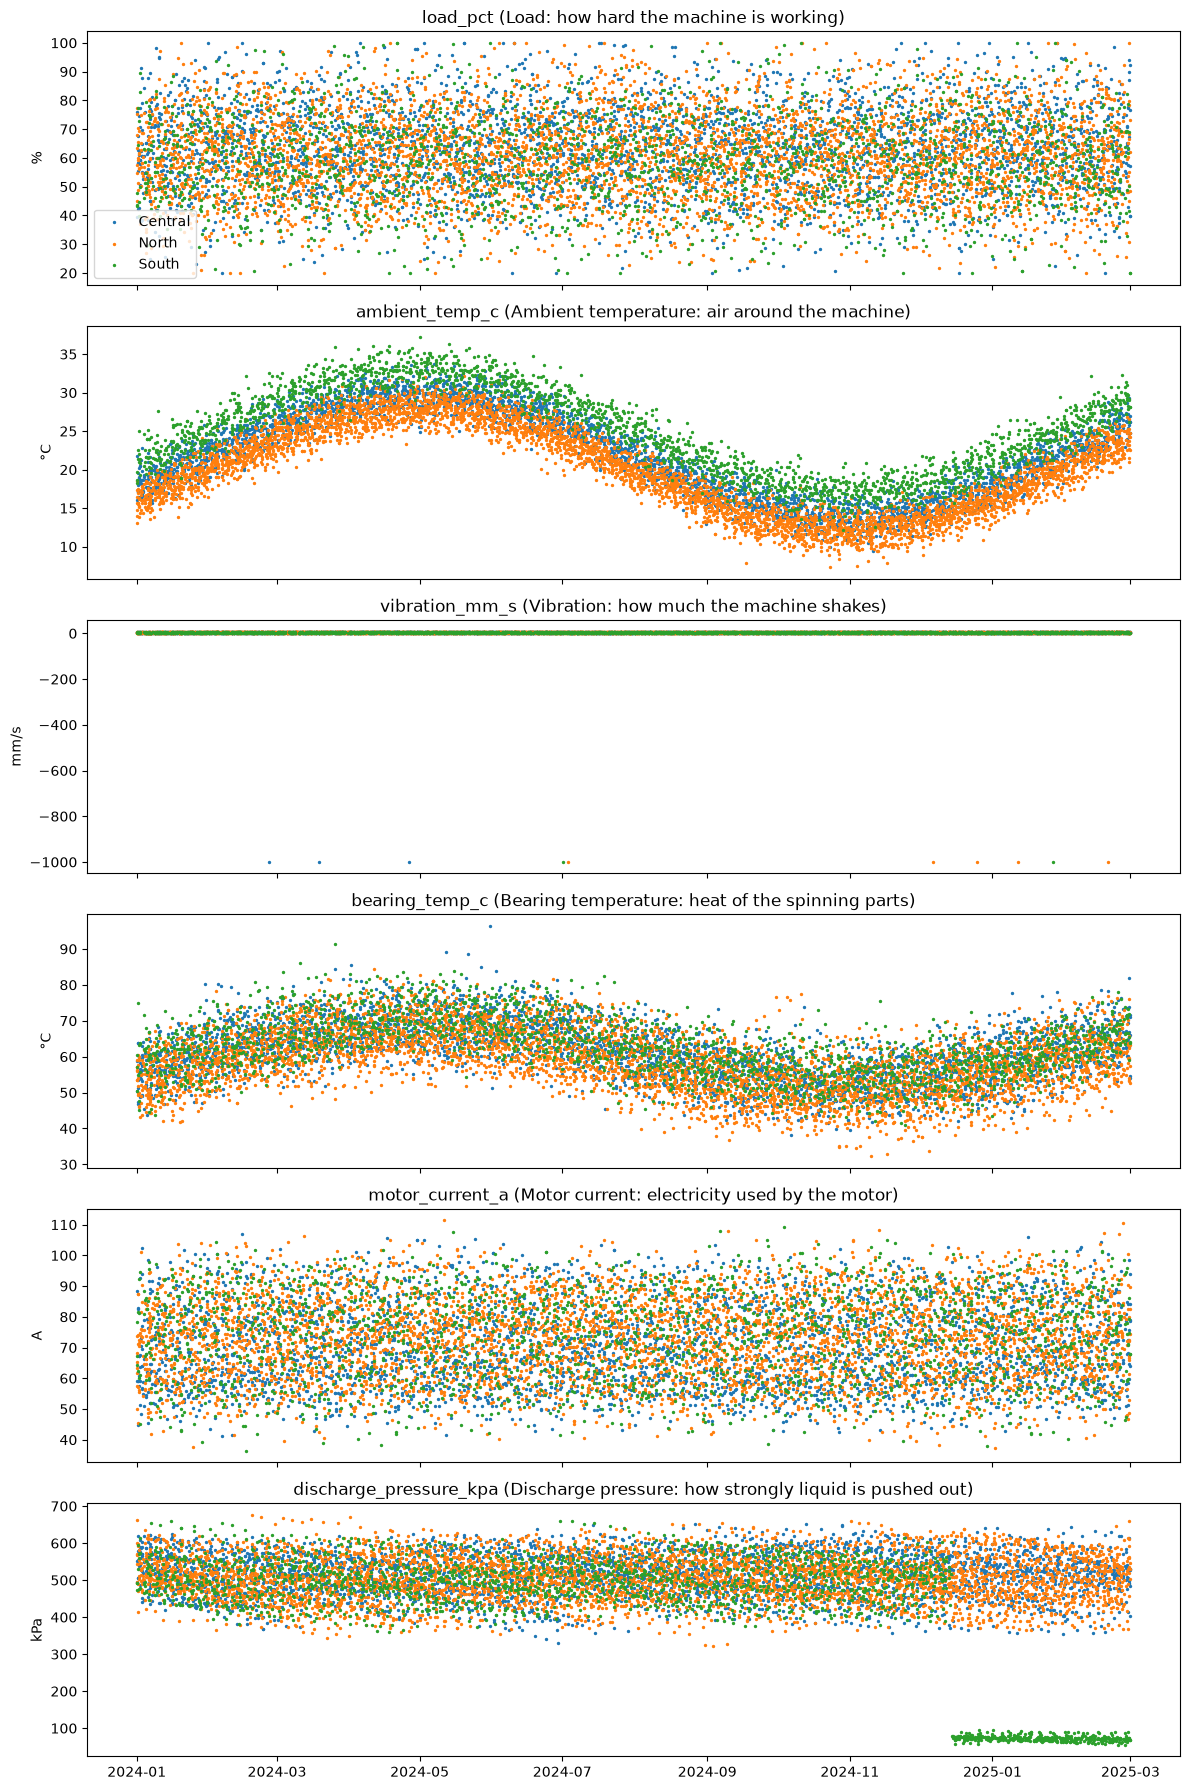

In [38]:
# Overview: every sensor over time, by site
sensors = {
    "load_pct":               ("Load: how hard the machine is working", "%"),
    "ambient_temp_c":         ("Ambient temperature: air around the machine", "°C"),
    "vibration_mm_s":         ("Vibration: how much the machine shakes", "mm/s"),
    "bearing_temp_c":         ("Bearing temperature: heat of the spinning parts", "°C"),
    "motor_current_a":        ("Motor current: electricity used by the motor", "A"),
    "discharge_pressure_kpa": ("Discharge pressure: how strongly liquid is pushed out", "kPa"),
}

fig, axes = plt.subplots(len(sensors), 1, figsize=(12, 3 * len(sensors)), sharex=True)

for ax, (col, (title, unit)) in zip(axes, sensors.items()):
    for site, part in df.groupby("site"):
        ax.scatter(part["observation_timestamp"], part[col], s=2, label=site)
        ax.set_title(f"{col} ({title})")
    ax.set_ylabel(unit)

axes[0].legend()
plt.tight_layout()
plt.show()

6. Vibration over time

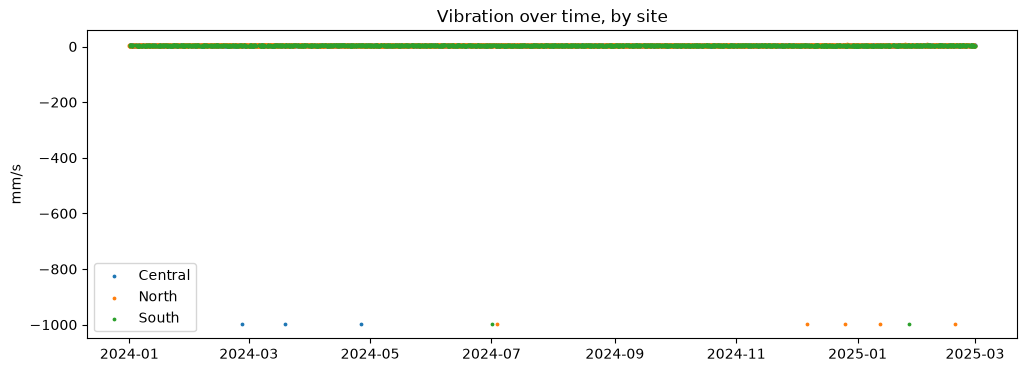

In [39]:
# Vibration over time, by site
fig, ax = plt.subplots(figsize=(12, 4))
for site, part in df.groupby("site"):
    ax.scatter(part["observation_timestamp"], part["vibration_mm_s"],
               s=3, label=site)
ax.set_title("Vibration over time, by site")
ax.set_ylabel("mm/s")
ax.legend()
plt.show()

7. Vibration, check negative values

In [40]:
# How many vibration readings are negative?
neg = df[df["vibration_mm_s"] < 0]
print("Negative vibration readings:", len(neg))
print(neg["vibration_mm_s"].value_counts())

print()
print("missing values for vibrartion BEFORE fix:", df["vibration_mm_s"].isna().sum())

Negative vibration readings: 10
vibration_mm_s
-999.0    10
Name: count, dtype: int64

missing values for vibrartion BEFORE fix: 103


8. Fixing the negative vibrartion readings (−999)

In [41]:
# −999 is a code for "no reading", so treat it as missing
df.loc[df["vibration_mm_s"] == -999, "vibration_mm_s"] = np.nan

print("Lowest vibration now:", df["vibration_mm_s"].min())
print("missing values for vibrartion AFTERfix:", df["vibration_mm_s"].isna().sum())

Lowest vibration now: 0.18
missing values for vibrartion AFTERfix: 113


9. Vibration chart after fix

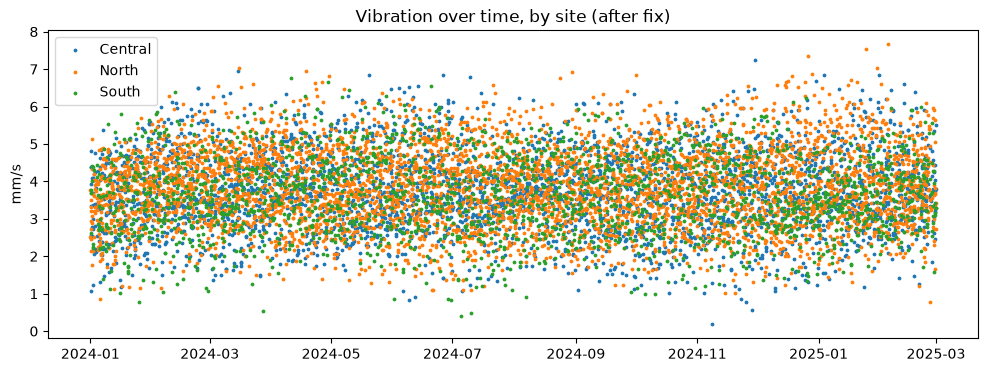

In [42]:
# Check the chart again after the fix
fig, ax = plt.subplots(figsize=(12, 4))
for site, part in df.groupby("site"):
    ax.scatter(part["observation_timestamp"], part["vibration_mm_s"],
               s=3, label=site)
ax.set_title("Vibration over time, by site (after fix)")
ax.set_ylabel("mm/s")
ax.legend()
plt.show()

10. Pressure over time
* A chart of pressure for each site, over time.


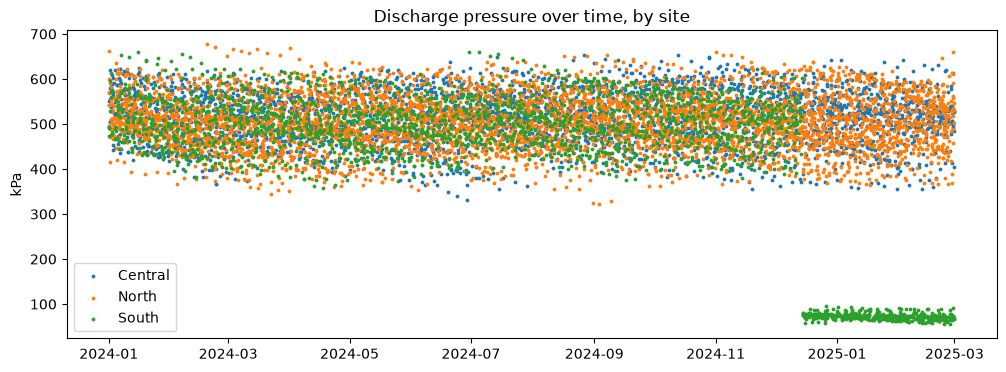

In [43]:
fig, ax = plt.subplots(figsize=(12, 4))
for site, part in df.groupby("site"):
    ax.scatter(part["observation_timestamp"], part["discharge_pressure_kpa"],
               s=3, label=site)
ax.set_title("Discharge pressure over time, by site")
ax.set_ylabel("kPa")
ax.legend()
plt.show()

11. What is normal pressure?

In [44]:
normal = df[df["observation_timestamp"] < "2024-12-01"]["discharge_pressure_kpa"]
normal.describe()

count    8192.000000
mean      507.451636
std        56.890452
min       322.800000
25%       467.875000
50%       508.200000
75%       548.700000
max       676.800000
Name: discharge_pressure_kpa, dtype: float64

12. Find when the drop starts

In [45]:
# Normal minimum is about 322, so below 300 is suspicious
low = df[df["discharge_pressure_kpa"] < 300]

print("Sites with low readings:")
print(low["site"].value_counts())
print()
print("First low reading:", low["observation_timestamp"].min())
print("Last low reading: ", low["observation_timestamp"].max())

Sites with low readings:
site
South    399
Name: count, dtype: int64

First low reading: 2024-12-14 16:23:00
Last low reading:  2025-02-28 21:47:00


13. Compare before and after, and convert

In [46]:
south = df[df["site"] == "South"]
change_date = low["observation_timestamp"].min()

before = south[south["observation_timestamp"] < change_date]
after = south[south["observation_timestamp"] >= change_date]

print("Drop starts on:", change_date)
print("South BEFORE median:", before["discharge_pressure_kpa"].median())
print("South AFTER median: ", after["discharge_pressure_kpa"].median())
print("AFTER x 6.895 (psi to kPa):", after["discharge_pressure_kpa"].median() * 6.895)
print()
day_start = change_date.normalize()   # 14 Dec at midnight (start of that day)

print("South rows from start of 14 Dec:", (south["observation_timestamp"] >= day_start).sum())
print("South rows from first low reading:", len(after))
print("Of those, low (< 300):", (after["discharge_pressure_kpa"] < 300).sum())

Drop starts on: 2024-12-14 16:23:00
South BEFORE median: 500.9
South AFTER median:  73.1
AFTER x 6.895 (psi to kPa): 504.02449999999993

South rows from start of 14 Dec: 401
South rows from first low reading: 399
Of those, low (< 300): 399


14. Fix the discharge pressure for the low readings (14/12/2024 - 28/2/2025)
* by converting to kPa, 1 psi = 6.895 kPa

In [47]:
psi_rows = ((df["site"] == "South")
            & (df["observation_timestamp"] >= change_date)
            & (df["discharge_pressure_kpa"] < 300))

df.loc[psi_rows, "discharge_pressure_kpa"] = df.loc[psi_rows, "discharge_pressure_kpa"] * 6.895

print("Rows fixed:", psi_rows.sum())
print("Lowest pressure now:", df["discharge_pressure_kpa"].min())

Rows fixed: 399
Lowest pressure now: 322.8


15. Check the chart again

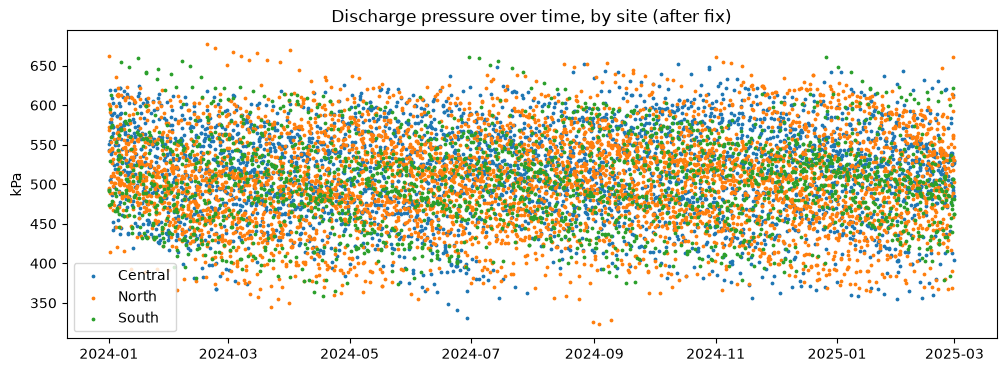

In [48]:
# Check the chart again after the fix
fig, ax = plt.subplots(figsize=(12, 4))
for site, part in df.groupby("site"):
    ax.scatter(part["observation_timestamp"], part["discharge_pressure_kpa"],
               s=3, label=site)
ax.set_title("Discharge pressure over time, by site (after fix)")
ax.set_ylabel("kPa")
ax.legend()
plt.show()

### check for duplicates

16. check for duplicates

In [49]:
# Duplicates: same machine, same time
cols_no_id = [c for c in df.columns if c != "record_id"]

print("Same machine + same time:",
      df.duplicated(subset=["machine_id", "observation_timestamp"]).sum())
print("Same in every column except record_id:",
      df.duplicated(subset=cols_no_id).sum())

# Show a few examples, side by side
dups = df[df.duplicated(subset=["machine_id", "observation_timestamp"], keep=False)]
dups.sort_values(["machine_id", "observation_timestamp"]).head(6)

Same machine + same time: 80
Same in every column except record_id: 80


,record_id,machine_id,observation_timestamp,site,machine_class,load_pct,ambient_temp_c,vibration_mm_s,bearing_temp_c,motor_current_a,discharge_pressure_kpa,corrective_orders_14d,unplanned_stops_14d,inspection_interval_days,fails_within_7d
2504,REC-002505,M005,2024-04-12 10:12:00,North,B,38.1,30.6,3.16,62.5,63.7,533.1,0,1,30,0
2505,REC-002506,M005,2024-04-12 10:12:00,North,B,38.1,30.6,3.16,62.5,63.7,533.1,0,1,30,0
2796,REC-002797,M006,2024-04-23 21:16:00,South,C,45.3,33.4,5.94,70.1,75.5,416.6,1,1,14,0
2797,REC-002798,M006,2024-04-23 21:16:00,South,C,45.3,33.4,5.94,70.1,75.5,416.6,1,1,14,0
2090,REC-002091,M012,2024-03-26 15:41:00,North,B,65.6,27.7,5.66,72.6,78.7,452.4,0,0,30,0
2091,REC-002092,M012,2024-03-26 15:41:00,North,B,65.6,27.7,5.66,72.6,78.7,452.4,0,0,30,0


17. Remove duplicates

In [50]:
# Remove copies, keep the first one
before = len(df)
df = df.drop_duplicates(subset=cols_no_id, keep="first")
print("Rows before:", before)
print("Rows after: ", len(df))
print("Removed:", before - len(df))

Rows before: 10414
Rows after:  10334
Removed: 80


### Machine class

18. Check total values for each machine class

In [51]:
# What values does machine_class have?
print(df["machine_class"].value_counts())
print()

# For machines with "unknown", what class do they have in their OTHER rows?
unknown_machines = df.loc[df["machine_class"] == "unknown", "machine_id"].unique()
known = df[df["machine_id"].isin(unknown_machines) & (df["machine_class"] != "unknown")]
known.groupby("machine_id")["machine_class"].unique()

machine_class
B          3688
A          3601
C          3030
unknown      15
Name: count, dtype: int64



machine_id
M008    [A]
M016    [B]
M028    [A]
M032    [C]
M033    [B]
M034    [A]
M046    [C]
M052    [B]
M055    [B]
M058    [C]
M060    [B]
M076    [C]
M084    [A]
M106    [C]
M112    [B]
Name: machine_class, dtype: object

19. check if any machine have MORE than one real class?

In [52]:
# Does any machine have MORE than one real class?
real = df[df["machine_class"] != "unknown"]
classes_per_machine = real.groupby("machine_id")["machine_class"].nunique()

print(classes_per_machine.value_counts())

machine_class
1    120
Name: count, dtype: int64


20. Fix unknown class

In [53]:
# Fill "unknown" using the class from the same machine's other rows
real_class = known.groupby("machine_id")["machine_class"].first()
mask = df["machine_class"] == "unknown"
df.loc[mask, "machine_class"] = df.loc[mask, "machine_id"].map(real_class)

print(df["machine_class"].value_counts())

machine_class
B    3694
A    3605
C    3035
Name: count, dtype: int64


# Save cleaned dataset

In [54]:
df.to_csv("../data/machine_observations_clean.csv", index=False)
print("Saved:", df.shape)

Saved: (10334, 15)
